# Performing DEG Pathway analysis (limma, R) on Pseudobulking DC2s from atlas
* Ovarian cancer samples only
* dataframes made previously (2026-04-10_PseudobulkingSampleType_fromNRcode.jpynb), separate for each DC subset and each has seperate metadata file
* Following code from NR 2025-02-12_Pseudo_Cancer_DEGS.
* Looking at DC2s only

In [1]:
library(limma)
library(edgeR)
library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:

# set directory
setwd('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk')

## Load data - DC2

In [3]:
list.files()

[1] "dc1_limma_DEG.csv"                           
 [2] "dc2_limma_DEG.csv"                           
 [3] "mregdc_limma_DEG.csv"                        
 [4] "OC_DC1"                                      
 [5] "OC_DC2"                                      
 [6] "OC_mregDC"                                   
 [7] "oc_pseudobulk_DC1_data.csv"                  
 [8] "oc_pseudobulk_DC2_data.csv"                  
 [9] "oc_pseudobulk_mregDC_data.csv"               
[10] "oc_pseudobulk_sampletype_metadata_DC1.csv"   
[11] "oc_pseudobulk_sampletype_metadata_DC2.csv"   
[12] "oc_pseudobulk_sampletype_metadata_mregDC.csv"
[13] "pseudobulk_DC1_data.csv"                     
[14] "pseudobulk_DC2_data.csv"                     
[15] "pseudobulk_metadata_DC1.csv"                 
[16] "pseudobulk_metadata_DC2.csv"                 
[17] "pseudobulk_metadata_mregDC.csv"              
[18] "pseudobulk_mregDC_data.csv"                  
[19] "pseudobulk_sampletype_metadata_DC1.csv"      
[20] "pseudobulk_sampletype_metadata_DC2.csv"      
[21] "pseudobulk_sampletype_metadata_mregDC.csv"   
[22] "PT-MT_limma_dc1.csv"                         
[23] "PT-MT_limma_dc2.csv"                         
[24] "PT-MT_limma_mregDC.csv"

In [4]:
#load data
sampleinfo <- read.csv("oc_pseudobulk_sampletype_metadata_DC2.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,metastatic tumour


In [5]:
dim(sampleinfo)

[1] 175   1

In [6]:
cts_DC2 <- read.csv("oc_pseudobulk_DC2_data.csv")
head(cts_DC2)

,X,GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL,⋯,PRJCA005422_HGSOC6_AS,PRJCA005422_HGSOC6_MT,PRJCA005422_HGSOC6_PT,PRJCA005422_HGSOC7_PT,PRJCA005422_HGSOC8_AS,PRJCA005422_HGSOC8_PT,PRJCA005422_HGSOC9_AS,PRJCA005422_HGSOC9_PT,PRJCA005422_HGSOC10_AS,PRJCA005422_HGSOC10_PT
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FAM87B,0,0,0,0,0,0,0,0,0,⋯,0,1,0,0,0,0,0,0,0,0
2,LINC00115,0,1,0,0,1,0,0,1,0,⋯,6,1,0,1,0,0,0,0,0,0
3,FAM41C,0,1,0,0,0,0,0,0,0,⋯,1,0,0,1,0,0,0,0,0,1
4,SAMD11,0,0,0,0,0,0,0,0,0,⋯,0,0,0,1,0,0,0,0,0,0
5,NOC2L,2,7,3,0,3,0,1,1,0,⋯,20,3,3,7,1,0,3,2,8,3
6,KLHL17,0,0,0,0,0,1,0,0,0,⋯,0,0,0,0,0,0,0,1,1,0


In [7]:
dim(cts_DC2)

[1] 15074   176

In [8]:
# set genes variables
genes <- data.frame(Symbol = row.names(cts_DC2))

In [9]:
# create DGEList variable
y <- DGEList(counts = cts_DC2, genes = genes)

Setting first column of `counts` as gene annotation.



In [10]:
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     0
2                                                     0
3                                                     0
4                                                     0
5                                                     2
6                                                     0
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
1                                              0
2                                              1
3                                              1
4                                              0
5                                              7
6                                              0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
1                                                        0
2                                                        0
3                                                        0
4                                                        0
5                                                        3
6                                                        0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
1                                                 0
2                                                 0
3                                                 0
4                                                 0
5                                                 0
6                                                 0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
1                                                         0
2                                                         1
3                                                         0
4                                                         0
5                                                         3
6                                                         0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
1                                                       0
2                                                       0
3                                                       0
4                                                       0
5                                                       0
6                                                       1
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
1                                                  0
2                                                  0
3                                                  0
4                                                  0
5                                                  1
6                                                  0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
1                                                          0
2                                                          1
3                                                          0
4                                                          0
5                                                          1
6                                                          0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
1                                        0
2                                        0
3                                        0
4                                        0
5                                        0
6                                        0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     0
2                                                     2
3                                                     3
4                                                     1
5                                                    13
6                                                     0
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
1                                        0
2                                        2
3    

In [11]:
dim(y)

[1] 15074   175

### Filtering:

In [12]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [13]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [14]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)

[1] 11209   175

### Normalise data

In [15]:
y <- calcNormFactors(y)
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     0
3                                                     0
5                                                     2
6                                                     0
8                                                     0
9                                                    22
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
2                                              1
3                                              1
5                                              7
6                                              0
8                                              1
9                                             31
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
2                                                        0
3                                                        0
5                                                        3
6                                                        0
8                                                        3
9                                                       49
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
2                                                 0
3                                                 0
5                                                 0
6                                                 0
8                                                 1
9                                                28
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
2                                                         1
3                                                         0
5                                                         3
6                                                         0
8                                                         0
9                                                        25
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
2                                                       0
3                                                       0
5                                                       0
6                                                       1
8                                                       5
9                                                      42
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
2                                                  0
3                                                  0
5                                                  1
6                                                  0
8                                                  1
9                                                 21
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
2                                                          1
3                                                          0
5                                                          1
6                                                          0
8                                                          2
9                                                          9
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
2                                        0
3                                        0
5                                        0
6                                        0
8                                        0
9                                        6
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     2
3                                                     3
5                                                    13
6                                                     0
8                                                     4
9                                                    51
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
2                                        2
3                                        0
5    

### Multi-dimensional scaling (MDS) plot to visualise relationship between samples

In [16]:
library(RColorBrewer)

In [17]:
# create vector of colours for sample types
sample_types <- unique(sampleinfo$sample_type_major2)
colors <- brewer.pal(n = length(sample_types), name = "Accent")

In [18]:
# set each sample type to a colour
sample_colors <- setNames(colors, sample_types)

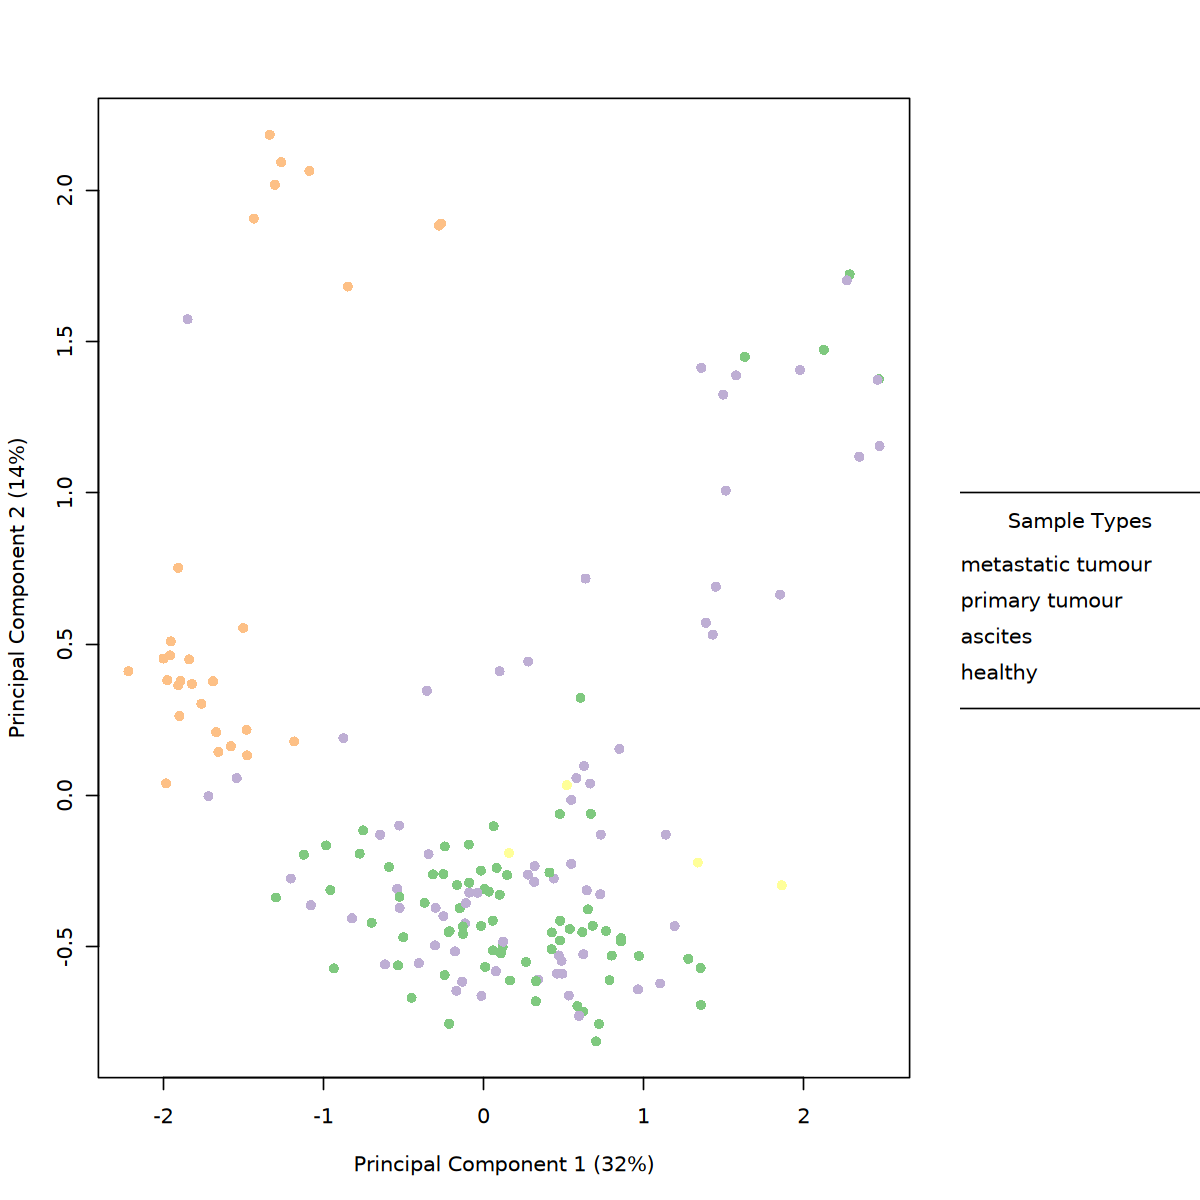

In [19]:
options(repr.plot.height=10, repr.plot.width=10)
layout(matrix(1:2, ncol = 2), widths = c(4, 1))  # Allocate space for the plot and legend

# Generate the MDS plot
plotMDS(y, 
        #labels = sampleinfo$sample_type_major2, 
        labels = NULL,
        col = sample_colors[sampleinfo$sample_type_major2], 
        pch = 16,
        top = 50, 
        gene.selection = "common", 
        prior.count = 5)

# Add a legend
par(mar = c(0, 0, 0, 0))  # Remove margins for the legend area
plot.new()               
legend("center",                        
       legend = sample_types,                 
       col = colors,                        
       pch = 16,                               
       title = "Sample Types")               
     

## Set Up Model

In [20]:
# setup model
design <- model.matrix(~ 0 + sample_type_major2, data = sampleinfo)

In [21]:
colnames(design) <- c("primary tumour","metastatic tumour","ascites","healthy")

In [22]:
head(design)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


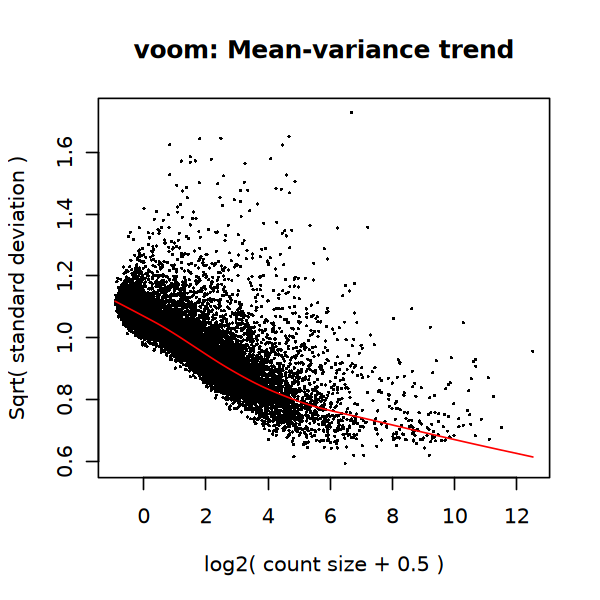

In [23]:
#voom - see here for good v bad voom plot: https://ucdavis-bioinformatics-training.github.io/2018-June-RNA-Seq-Workshop/thursday/DE.html
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [24]:
# lmFit
fit <- lmFit(v, design)

## Contrast - compare primary to the rest

In [25]:
#duplicate data
design2 <- design
head(design2)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


In [26]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

In [27]:
head(design2)

,primary_tumour,metastatic_tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


In [28]:
# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour - (metastatic_tumour + healthy + ascites), levels=design2) #compare primary to rest
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [29]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf) #Benjamini-Hochberg (BH) procedure is a statistical method used in multiple hypothesis testing to control the False Discovery Rate (FDR)

In [30]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)
head(tt1)
     

       primary_tumour - (metastatic_tumour + healthy + ascites)
Down                                                      11209
NotSig                                                        0
Up                                                            0

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6221,TMSB4X,6221,-27.26692,13.53797,-119.5987,8.828162e-179,9.895486e-175,381.6916
4933,HLA-DRA,4933,-28.33691,13.93177,-111.9600,1.734690e-173,6.481380e-170,372.3806
2504,PTMA,2504,-23.56714,11.60909,-112.4888,7.271263e-174,4.075180e-170,366.9111
10902,B2M,10902,-26.48459,13.09329,-105.4238,1.134408e-168,2.119263e-165,361.0612
11883,RPL13,11883,-24.83763,12.27949,-105.4991,9.946880e-169,2.119263e-165,359.8061
8930,RPS24,8930,-24.31602,12.01282,-105.4914,1.008054e-168,2.119263e-165,359.2933


## Compare primary to each other state

In [31]:
# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour-metastatic_tumour,primary_tumour-healthy,primary_tumour-ascites, levels=design2) #compare primary to every other individually
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)
    

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [32]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf)
tt2 <- topTable(fit2, coef=2, adjust="BH", number = Inf)
tt3 <- topTable(fit2, coef=3, adjust="BH", number = Inf)

In [34]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)


       primary_tumour - metastatic_tumour primary_tumour - healthy
Down                                  519                     3056
NotSig                              10570                     6004
Up                                    120                     2149
       primary_tumour - ascites
Down                       2523
NotSig                     7102
Up                         1584

In [35]:
head(tt1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,14192,-7.172775,8.061751,-16.44486,3.454625e-38,3.872290e-34,75.59583
2181,NR4A2,2181,-6.283017,8.034056,-14.33984,5.913278e-32,3.314096e-28,61.62468
9530,NR4A1,9530,-5.817679,7.428508,-11.95837,7.459203e-25,2.787007e-21,45.67630
1262,PTGS2,1262,-6.713193,5.891439,-11.64059,6.504013e-24,1.822587e-20,43.48866
1401,ATF3,1401,-5.565390,7.097458,-11.37864,3.851633e-23,8.634590e-20,41.82205
10247,GPR183,10247,-4.562681,9.016367,-11.16021,1.688578e-22,3.154545e-19,40.46262


In [36]:
# 1. Assign the column values to row names
rownames(tt1) <- tt1$X
rownames(tt2) <- tt2$X
rownames(tt3) <- tt3$X

In [37]:
# select top 250 up, and 250 down genes from tt1
up_genes_tt1 <- tt1 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character
down_genes_tt1 <- tt1 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character

In [38]:
plot_genes_tt1 <- c(up_genes_tt1, down_genes_tt1)

In [39]:
# log normalise transformed gene expression
mat_tt1 <- v$E[plot_genes_tt1, ]
dim(mat_tt1)

[1] 620 175

In [40]:
library(pheatmap)

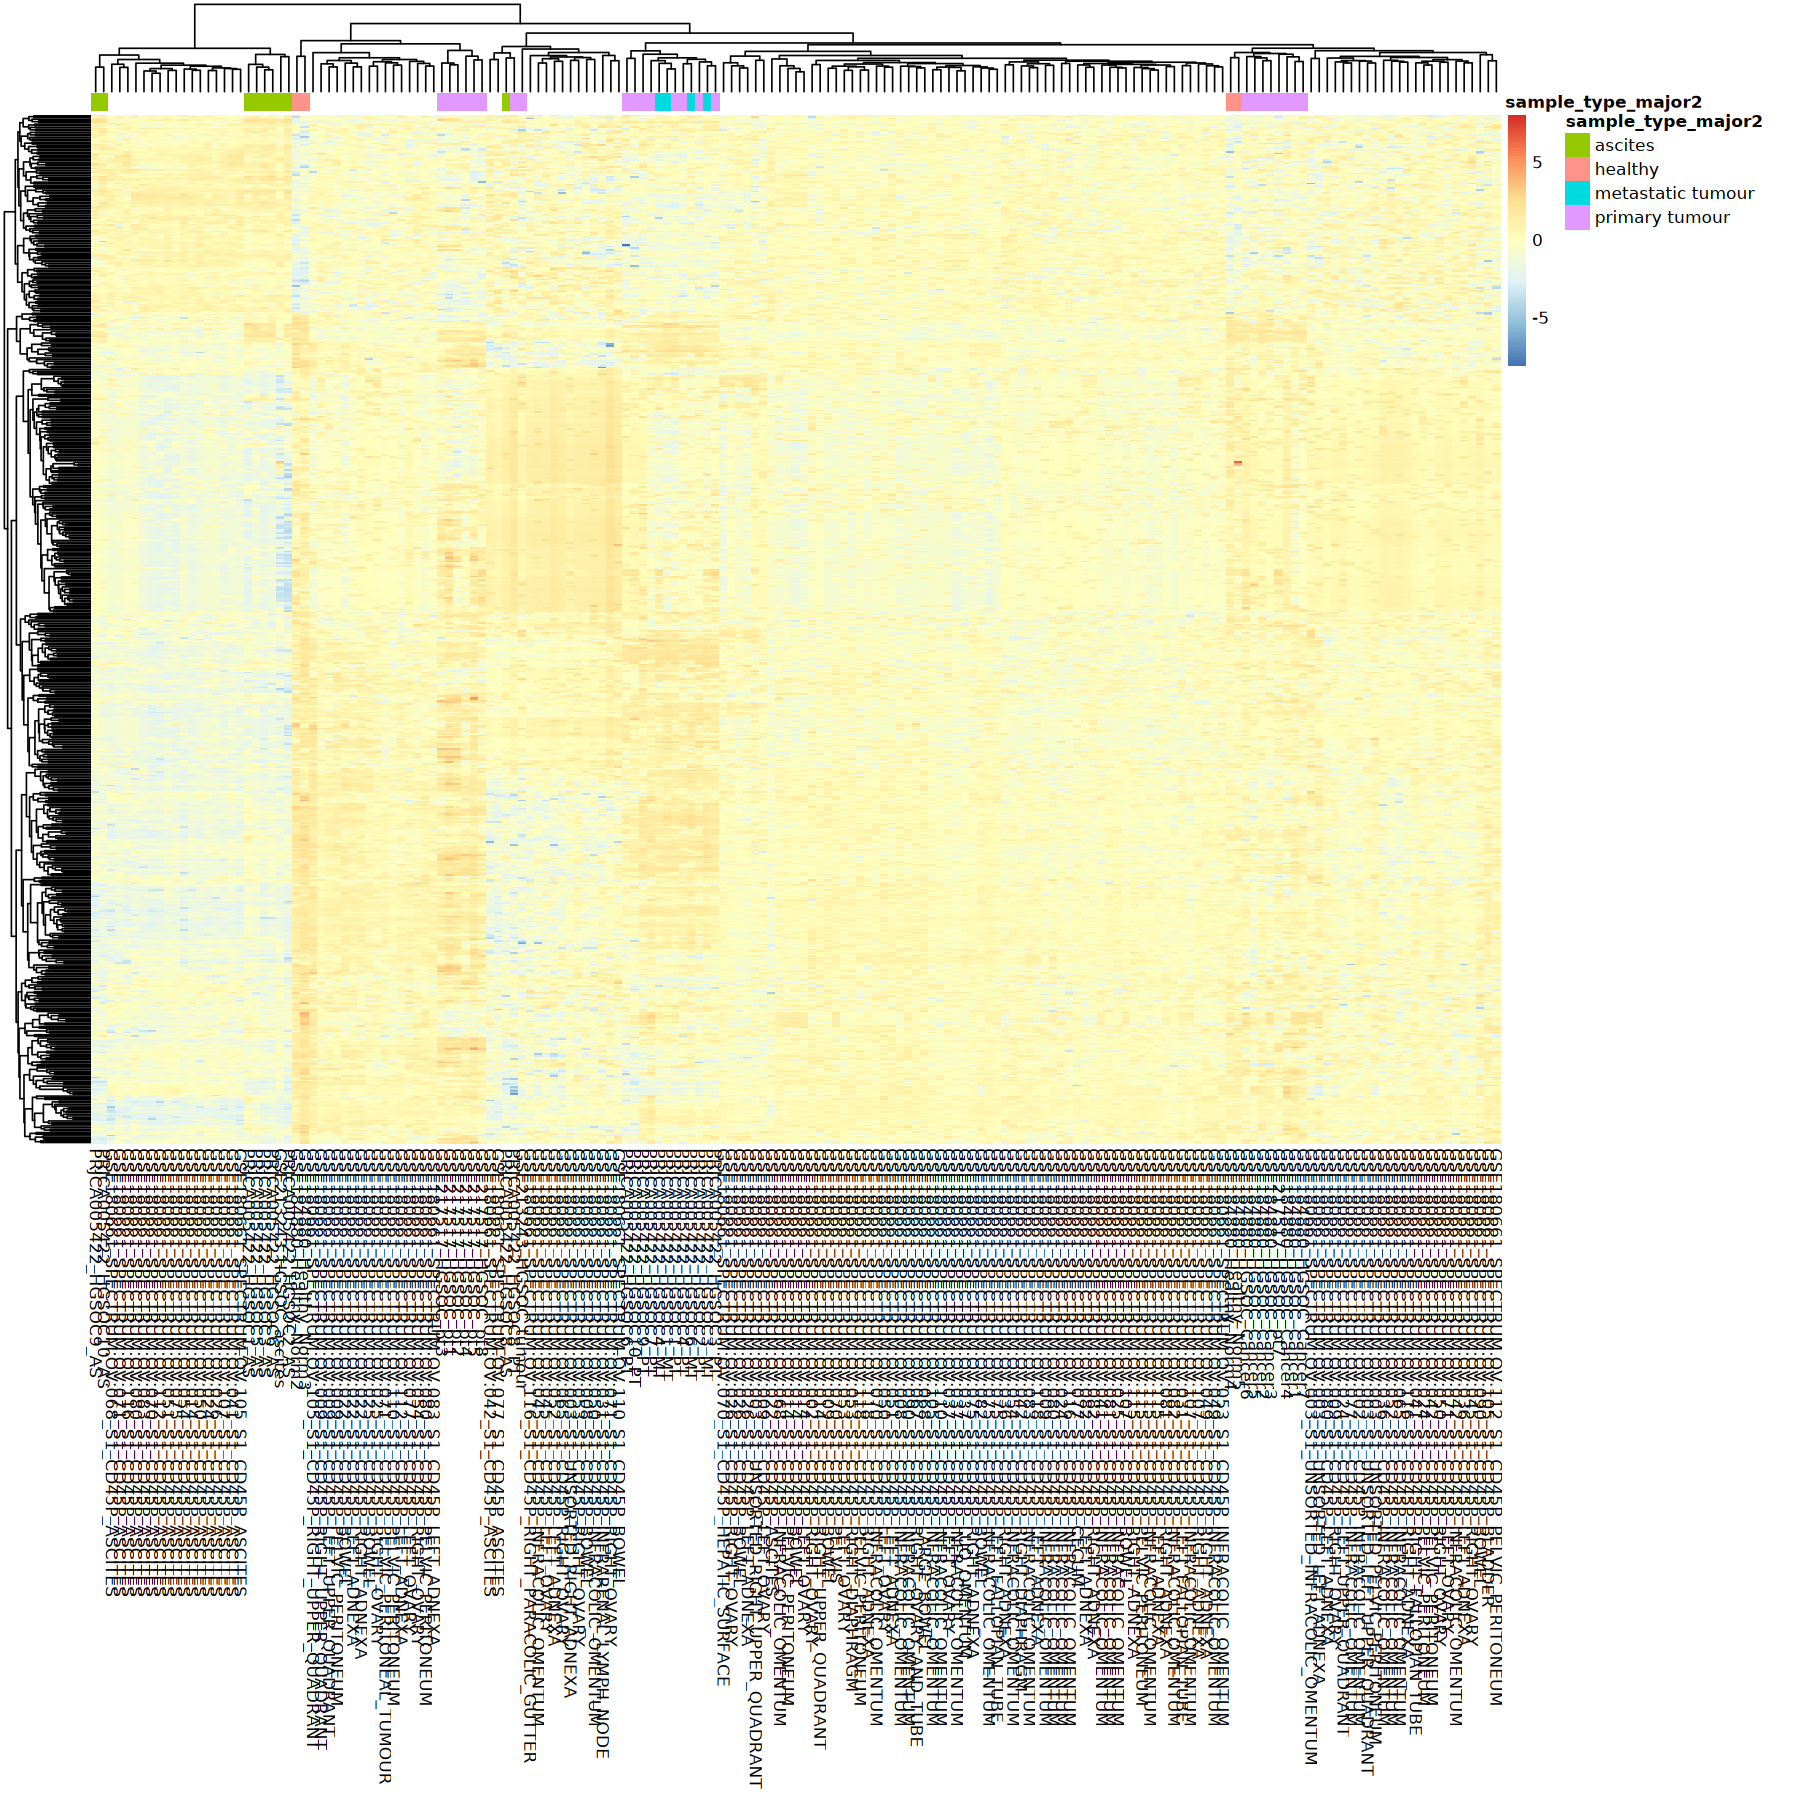

In [41]:
options(repr.plot.height=15, repr.plot.width=15)
pheatmap(mat_tt1, scale = "row", show_rownames = FALSE, annotation_col = sampleinfo[, "sample_type_major2", drop=FALSE])

## Look at select comparisons

In [42]:
dim(tt1) #tt1 is primary_tumour-metastatic_tumour?

[1] 11209     8

In [43]:
getwd()

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk"

In [44]:
# export as csv
write.csv(tt1, "PT-MT_limma_dc2.csv", quote = FALSE, row.names = FALSE)

## Compare all contrasts

In [45]:
# subgroup significant up and down degs from tt2
# 0.58 equivalent to 1.5 fold change
tt1_up_sig <- tt1[tt1$logFC > 0.58 & tt1$adj.P.Val < 0.05, ]
tt1_dn_sig <- tt1[tt1$logFC < -0.58 & tt1$adj.P.Val < 0.05, ]
# extract only the gene names
tt1_up_sig_list <- rownames(tt1_up_sig)
tt1_dn_sig_list <- rownames(tt1_dn_sig)
#tt1 is the comparison of the primary vs the metastatic

# subgroup significant up and down degs from tt2
# 0.58 equivalent to 1.5 fold change
tt2_up_sig <- tt2[tt2$logFC > 0.58 & tt2$adj.P.Val < 0.05, ]
tt2_dn_sig <- tt2[tt2$logFC < -0.58 & tt2$adj.P.Val < 0.05, ]
# extract only the gene names
tt2_up_sig_list <- rownames(tt2_up_sig)
tt2_dn_sig_list <- rownames(tt2_dn_sig)
#tt2 is the comparison of the primary vs the healthy

# subgroup significant up and down degs from tt3
# 0.58 equivalent to 1.5 fold change
tt3_up_sig <- tt3[tt3$logFC > 0.58 & tt3$adj.P.Val < 0.05, ]
tt3_dn_sig <- tt3[tt3$logFC < -0.58 & tt3$adj.P.Val < 0.05, ]
# extract only the gene names
tt3_up_sig_list <- rownames(tt3_up_sig)
tt3_dn_sig_list <- rownames(tt3_dn_sig)
#tt3 is the comparison of primary vs the ascites

In [46]:
tt1_up_sig_list

[1] "APPL1"    "HCK"      "PRMT2"    "DSC2"     "MTIF2"    "TSR2"    
  [7] "SP100"    "KTN1"     "HDAC7"    "SAMHD1"   "KIT"      "OGFR"    
 [13] "IL21R"    "TLN1"     "ING4"     "MS4A4E"   "PALLD"    "AP2A1"   
 [19] "ZNF106"   "FUT7"     "PIK3CG"   "PTGES2"   "SUSD1"    "ALOX5"   
 [25] "PGS1"     "YKT6"     "NME6"     "GNL3L"    "SH2D3C"   "ZNF296"  
 [31] "PARP12"   "IRF9"     "SLC12A9"  "TARS"     "TGFBR2"   "CD180"   
 [37] "LRP10"    "PROCR"    "MFSD3"    "IDH1"     "BTLA"     "CES2"    
 [43] "STARD7"   "CCDC12"   "RCSD1"    "ZBTB7B"   "PNPLA6"   "SLC39A7" 
 [49] "NOB1"     "CDC123"   "PARP4"    "SLC8A1"   "OAS3"     "RGP1"    
 [55] "ARHGAP30" "MILR1"    "TBCC"     "ALPK1"    "DTX3L"    "MAX"     
 [61] "FUCA1"    "GALM"     "DOCK8"    "EPN1"     "MIEF1"    "GAS6"    
 [67] "IFITM2"   "ARNTL"    "CSK"      "ZNF431"   "WDR83"    "CMPK2"   
 [73] "UBE4A"    "PHF11"    "SMARCC2"  "PEX26"    "SPTLC1"   "DNAJC13" 
 [79] "LILRB1"   "IFIT5"    "PARM1"    "ACTR8"    "FLVCR2"   "ASCC1"   
 [85] "HMGN4"    "MMS19"    "CCDC137"  "CFI"      "C16orf86" "LANCL1"  
 [91] "GUF1"     "PPP1R16B" "ARHGEF3"  "C1RL"     "DAXX"     "ENDOD1"  
 [97] "BAG4"     "BRD3"     "RAB14"    "COASY"    "OXLD1"    "FANCF"   
[103] "DHX57"    "PTPRO"    "CCDC127"  "TRIM14"   "SPINT2"   "DENND1C" 
[109] "P2RY6"    "ADCK2"    "RNF170"   "LILRB4"   "PANK2"    "STAT2"   
[115] "ACP5"     "GLB1"     "REST"     "UGCG"     "TM9SF2"   "ITGA4"

In [47]:
tt1_dn_sig_list

[1] "FOSB"       "NR4A2"      "NR4A1"      "PTGS2"      "ATF3"      
  [6] "GPR183"     "DUSP1"      "SGK1"       "DUSP2"      "RASGEF1B"  
 [11] "MAFF"       "RGS1"       "GADD45B"    "FOSL2"      "NRARP"     
 [16] "RGS2"       "KDM6B"      "CD83"       "MCL1"       "NR4A3"     
 [21] "PPP1R15A"   "ARL5B"      "NAMPT"      "COL1A2"     "IL1B"      
 [26] "CCL3"       "CXCL2"      "ZFP36"      "CCL4L2"     "GRASP"     
 [31] "PMAIP1"     "EREG"       "HCAR2"      "SPARC"      "FOS"       
 [36] "CXCL3"      "CHMP1B"     "SOCS3"      "BCAS2"      "COL1A1"    
 [41] "COL3A1"     "IL1A"       "ZNF331"     "IL10"       "IER3"      
 [46] "TNFSF9"     "JUN"        "RGCC"       "RILPL2"     "HBB"       
 [51] "TIPARP"     "ANKRD28"    "VEGFA"      "OTUD1"      "HCAR3"     
 [56] "JOSD1"      "HBEGF"      "CCL4"       "HSPA1B"     "CYB5D1"    
 [61] "JUNB"       "C11orf96"   "MYADM"      "LDLR"       "TNF"       
 [66] "NFKBIZ"     "ARL4A"      "KLF4"       "PHACTR1"    "JUND"      
 [71] "SRSF7"      "NFKBIA"     "SOD2"       "PLA1A"      "PPP1R15B"  
 [76] "EGR3"       "ANKRD9"     "HES4"       "DCN"        "TNFRSF10B" 
 [81] "GEM"        "IER2"       "IER5"       "IL1RN"      "SLC26A11"  
 [86] "YBX3"       "PRDM1"      "KLF6"       "RRAD"       "CREM"      
 [91] "TNFAIP3"    "HSPA1A"     "LUCAT1"     "LMNA"       "HSP90AA1"  
 [96] "OSM"        "INSIG1"     "SRSF3"      "BHLHE40"    "TREM1"     
[101] "SRGN"       "PHLDA1"     "CXCR4"      "IGFBP4"     "SLC2A3"    
[106] "NFIL3"      "PLAUR"      "PURB"       "G0S2"       "GABARAPL1" 
[111] "PRR4"       "DNAJB1"     "TCHH"       "LINC01116"  "BCL2A1"    
[116] "SAV1"       "KLF10"      "DBI"        "EIF4A3"     "CSRNP1"    
[121] "PTGER4"     "B3GNT5"     "AC144652.1" "C1R"        "MXD1"      
[126] "HBA2"       "PLEKHG2"    "ATP1B3"     "RBP1"       "STX11"     
[131] "INHBA"      "NEAT1"      "RIPK2"      "EGR2"       "EGR1"      
[136] "PHLDB1"     "PTX3"       "CDK2AP1"    "DUSP8"      "CCNL1"     
[141] "HOMER1"     "H3F3B"      "HSPE1"      "SNAI1"      "UBC"       
[146] "ERN1"       "COL6A3"     "SAT1"       "PRDM8"      "CYCS"      
[151] "CEBPD"      "SERPINE1"   "AREG"       "PHLDA2"     "C17orf107" 
[156] "CCRL2"      "POLR2J3"    "EDEM1"      "SERPINB9"   "USP36"     
[161] "SDE2"       "SYAP1"      "TUBB2A"     "SH3BP5"     "THAP2"     
[166] "IRF8"       "EXO1"       "MGST1"      "C5AR1"      "LIF"       
[171] "TRIB1"      "DNAJB5"     "CLK1"       "SNAPC1"     "NCR3LG1"   
[176] "FGFR1"      "NEU4"       "LINC00309"  "ZNF267"     "TMEM120B"  
[181] "GZF1"       "CD69"       "AVPI1"      "MT-CYB"     "SPARCL1"   
[186] "RGS13"      "NAF1"       "CALD1"      "GSTM3"      "ARL4C"     
[191] "ADRA2B"     "PIM3"       "UBE2S"      "CD55"       "COL6A1"    
[196] "ZC3H12A"    "KIFC1"      "SAMSN1"     "AGO2"       "SIK1"      
[201] "VENTX"      "SCML1"      "MIDN"       "IL10RB"     "IRS2"      
[206] "PLK3"       "FAM149A"    "PPP1CB"     "OLR1"       "IL1RL2"    
[211] "COL6A2"     "MAP2K3"     "DUSP10"     "ADIRF"      "PTGER2"    
[216] "PSMA2"      "GNA13"      "DUSP5"      "YPEL4"      "TNIP3"     
[221] "LGALS3"     "ANXA1"      "GALR2"      "TAF13"      "CCL20"     
[226] "NEU1"       "PID1"       "EMP1"       "MYL9"       "FLT1"      
[231] "YPEL5"      "MGP"        "IGFBP2"     "LOH12CR2"   "PFKFB3"    
[236] "TMEM158"    "STX4"       "HSPH1"      "SLC3A2"     "PDE4B"     
[241] "SDR42E2"    "CFH"        "NRIP3"      "NR1D1"      "EGOT"      
[246] "REV3L"      "CLCF1"      "ALDOA"      "MIR155HG"   "DUSP4"     
[251] "BIRC3"      "MT1M"       "RAB4B"      "CD109"      "HMGCS1"    
[256] "IL1R2"      "TUBB4B"     "VPS37B"     "LUM"        "SYNJ2"     
[261] "SERINC5"    "NKRF"       "PRNP"       "SLC7A5"     "IDI1"      
[266] "AKAP12"     "LAMB2"      "GLUL"       "BIRC5"      "RPS10"     
[271] "GADD45G"    "FANCB"      "CNN3"       "PTTG1"      "CDC42EP4"  
[276] "SPAG5"      "BTG2"       "TMEM71"     "HNRNPU"     "FNIP1"     
[281] "VDR"        "MSMO1"

In [45]:
# Combine into dataframe 
#up_genes_lists <- list(primary_tumour-metastatic_tumour_up = tt1_up_sig_list, primary_tumour-healthy_up = tt2_up_sig_list, primary_tumour-ascites_up = tt3_up_sig_list)

In [48]:
# Combine into dataframe 
up_genes_lists <- list(PT_MT_up = tt1_up_sig_list, PT_H_up = tt2_up_sig_list, PT_A_up = tt3_up_sig_list)

In [49]:
# combine into dataframe
down_genes_lists <- list(PT_MT_dn = tt1_dn_sig_list, PT_H_dn = tt2_dn_sig_list, PT_A_dn = tt3_dn_sig_list)
     

In [50]:
# Convert to dataframe, filling missing values with NA
df_up_genes <- data.frame(lapply(up_genes_lists, function(x) { length(x) <- max(lengths(up_genes_lists)); x }))
df_down_genes <- data.frame(lapply(down_genes_lists, function(x) { length(x) <- max(lengths(down_genes_lists)); x }))
     

In [51]:
head(df_up_genes)

,PT_MT_up,PT_H_up,PT_A_up
,<chr>,<chr>,<chr>
1,APPL1,SAMHD1,CD72
2,HCK,CD72,IFITM2
3,PRMT2,STON2,SAMHD1
4,DSC2,CD1D,ADD3
5,MTIF2,ADD3,STON2
6,TSR2,IFITM2,PRAM1


In [52]:
head(df_down_genes)

,PT_MT_dn,PT_H_dn,PT_A_dn
,<chr>,<chr>,<chr>
1,FOSB,FOSB,FOSB
2,NR4A2,NR4A2,NR4A2
3,NR4A1,RGS1,RGS1
4,PTGS2,RASGEF1B,RASGEF1B
5,ATF3,SGK1,SGK1
6,GPR183,NR4A1,NR4A1


In [53]:
# export to csv
write.csv(df_up_genes, "OC_DC2/df_up_genes.csv", quote = FALSE, row.names = FALSE)
write.csv(df_down_genes, "OC_DC2/df_down_genes.csv", quote = FALSE, row.names = FALSE)

In [54]:
class(tt1)

[1] "data.frame"

In [55]:
head(tt1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,FOSB,14192,-7.172775,8.061751,-16.44486,3.454625e-38,3.872290e-34,75.59583
NR4A2,NR4A2,2181,-6.283017,8.034056,-14.33984,5.913278e-32,3.314096e-28,61.62468
NR4A1,NR4A1,9530,-5.817679,7.428508,-11.95837,7.459203e-25,2.787007e-21,45.67630
PTGS2,PTGS2,1262,-6.713193,5.891439,-11.64059,6.504013e-24,1.822587e-20,43.48866
ATF3,ATF3,1401,-5.565390,7.097458,-11.37864,3.851633e-23,8.634590e-20,41.82205
GPR183,GPR183,10247,-4.562681,9.016367,-11.16021,1.688578e-22,3.154545e-19,40.46262


In [56]:

write.csv(tt1, "OC_DC2/tt1_DC2.csv", quote = FALSE, row.names = TRUE)
write.csv(tt2, "OC_DC2/tt2_DC2.csv", quote = FALSE, row.names = TRUE)
write.csv(tt3, "OC_DC2/tt3_DC2.csv", quote = FALSE, row.names = TRUE)

In [54]:
tt1_DC1 <- read.csv("OC_DC2/tt1_DC2.csv", row.names = 1)

## Performing GSEA using clusterprofiler

In [ ]:
#if (!require("BiocManager", quietly = TRUE))
 #   install.packages("BiocManager")
#
#BiocManager::install("clusterProfiler")


Bioconductor version '3.20' is out-of-date; the current release version '3.22'
  is available with R version '4.5'; see https://bioconductor.org/install

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'clusterProfiler'

also installing the dependencies ‘tweenr’, ‘Biostrings’, ‘fastmatch’, ‘ggplotify’, ‘ggforce’, ‘ape’, ‘tidytree’, ‘treeio’, ‘R.oo’, ‘R.methodsS3’, ‘RSQLite’, ‘KEGGREST’, ‘fgsea’, ‘aplot’, ‘ggfun’, ‘ggnewscale’, ‘ggtangle’, ‘scatterpie’, ‘ggtree’, ‘R.utils’, ‘AnnotationDbi’, ‘DOSE’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘qvalue’, ‘yulab.utils’


Warning message in install.packages(...):
“installation of package ‘ggtree’ had non-zero exit status”
Warning message in install.packages(...):
“installation of package ‘enrichplot’ had no

In [ ]:
#if (!require("BiocManager", quietly = TRUE))
 #   install.packages("BiocManager")
#
#BiocManager::install("org.Hs.eg.db")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'org.Hs.eg.db'

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Old packages: 'backports', 'bit64', 'cli', 'cpp11', 'curl', 'devtools',
  'dplyr', 'ellipsis', 'fastDummies', 'fs', 'furrr', 'ggplot2', 'glue',
  'hardhat', 'igraph', 'lava', 'lazyeval', 'limma', 'lobstr', 'magrittr',
  'nlme', 'openssl', 'pak', 'parallelly', 'pkgload', 'processx', 'progressr',
  'ps', 'purrr', 'ragg', 'Rcpp', 'RcppArmadillo', 'recipes', 'rmarkdown',
  'rpart', 'S7', 'Seurat', 'SeuratObject', 'sourcetools', 'spatstat.explore',
  'spatstat.geom', 'spatstat.random', 'terra', 'textshaping', 'tinytex',
  'vctrs', 'vroom'



In [ ]:
#BiocManager::install("enrichplot")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'enrichplot'

also installing the dependency ‘ggtree’


Warning message in install.packages(...):
“installation of package ‘ggtree’ had non-zero exit status”
Warning message in install.packages(...):
“installation of package ‘enrichplot’ had non-zero exit status”
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Old packages: 'backports', 'bit64', 'cli', 'cpp11', 'curl', 'devtools',
  'dplyr', 'ellipsis', 'fastDummies', 'fs', 'furrr', 'ggplot2', 'glue',
  'hardhat', 'igraph', 'lava', 'lazyeval', 'limma', 'lobstr', 'magrittr',
  'nlme', 'openssl', 'pak', 'parallelly', 'pkgload', 'processx', 'progressr',
  'ps', 'purrr', 'ragg', 'Rcpp', 'RcppArmadillo', 'recipes', 'rmarkdown

In [56]:
library(clusterProfiler)



clusterProfiler v4.14.0 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

G Yu. Thirteen years of clusterProfiler. The Innovation. 2024,
5(6):100722


Attaching package: ‘clusterProfiler’


The following object is masked from ‘package:stats’:

    filter




In [57]:
library(enrichplot)
library(dplyr)



enrichplot v1.26.1 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287



In [ ]:
#install.packages("msigdbr")

also installing the dependency ‘babelgene’


Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [59]:
install.packages("org.Hs.eg.db")

Warning message:
“package ‘org.Hs.eg.db’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [60]:
library(msigdbr)
library('org.Hs.eg.db')

Loading required package: AnnotationDbi

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following object is masked from ‘package:limma’:

    plotMA


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: Biobase

Welcome to Bioconductor

    Vignettes contain introductory material; view with
    'browseVignettes()'

In [160]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Rocky Linux 9.7 (Blue Onyx)

Matrix products: default
BLAS/LAPACK: /home/uqlbukat/miniforge3/envs/R_env/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Australia/Brisbane
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] org.Hs.eg.db_3.20.0  AnnotationDbi_1.68.0 IRanges_2.40.1      
 [4] S4Vectors_0.44.0     Biobase_2.66.0       BiocGenerics_0.52.0 
 [7] BiocManager_1.30.27  pheatmap_1.0.13      RColorBrewer_1.1-3  


## Show which genes sets will be used for the comparison

From the meeting with KR-NR-KT on 13/4/26
* IFN --> HALLMARK
* TNF --> HALLMARK
* Ag presentation --> KEGG
* Migration --> KEGG
* Phagocytosis --> KEGG

Load the packages to look at the KEGG and HALLMARK gene set pathways

In [63]:
msigdbr_species()

species_name,species_common_name
<chr>,<chr>
Anolis carolinensis,"Carolina anole, green anole"
Bos taurus,"bovine, cattle, cow, dairy cow, domestic cattle, domestic cow, ox, oxen"
Caenorhabditis elegans,NA
Canis lupus familiaris,"dog, dogs"
Danio rerio,"leopard danio, zebra danio, zebra fish, zebrafish"
Drosophila melanogaster,fruit fly
Equus caballus,"domestic horse, equine, horse"
Felis catus,"cat, cats, domestic cat"
Gallus gallus,"bantam, chicken, chickens, Gallus domesticus"


In [61]:
#Load MsigDB  GO BP terms for homo sapiens
msig_go_bp <- msigdbr(species = "Homo sapiens", category = "C5", subcategory = "GO:BP")

Warning message:
“The `category` argument of `msigdbr()` is deprecated as of msigdbr 10.0.0.
ℹ Please use the `collection` argument instead.”
Warning message:
“The `subcategory` argument of `msigdbr()` is deprecated as of msigdbr 10.0.0.
ℹ Please use the `subcollection` argument instead.”


ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10001 milliseconds


In [65]:
#Load MsigDB  GO BP terms for homo sapiens
msig_go_bp <- msigdbr(species = "Homo sapiens", collection = "C5", subcollection = "GO:BP")

ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10000 milliseconds


In [ ]:
# Extract the gene sets of interest
immune_go_terms <- msig_go_bp %>%
  filter(gs_name %in% c("GOBP_POSITIVE_REGULATION_OF_IMMUNE_RESPONSE",
                        "GOBP_NEGATIVE_REGULATION_OF_IMMUNE_RESPONSE"))